# Project 1: Wealth Inequality in Denmark
Starter notebook. Add your names, code and interpretations. Keep your simulation module (.py) beside this notebook.

**Group name:** 
**Members:** Hana and Clara

The tasks are in the project PDF. [Course plan: deadline and rules](https://github.com/NumEconCopenhagen/ProgEcon-lectures/blob/main/PLAN_autumn26.md#projects-and-exam) · [Hand-in: Dropbox file request](https://www.dropbox.com/request/6cn75p9izf51x3am6kfe) (one `GroupName_P1_v1.zip` per group)

## Download function
`download('FORMUE16', PERCENTIL='*', ...)` asks Statistics Denmark for table FORMUE16. Each keyword is one **variable code** and its value selects the rows you want; `'*'` selects all values. This is the same information as the `variables` list in the Lecture 10 API notebook, written more compactly, and it needs no extra package. The result is a DataFrame with one column per variable and the number in `value`.

To find the codes of another table, open its table information in your browser, for example [FORMUE15](https://api.statbank.dk/v1/tableinfo/FORMUE15?lang=en&format=JSON).

In [2]:
from io import BytesIO
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(table, **selectors):
    """Download a StatBank table as a DataFrame. Each keyword is one variable code; '*' selects all values."""
    url = f'https://api.statbank.dk/v1/data/{table}/CSV'
    params = dict(lang='en', valuePresentation='Code', **selectors)
    response = requests.get(url, params=params, timeout=45)
    response.raise_for_status()
    frame = pd.read_csv(BytesIO(response.content), sep=';', dtype=str, encoding='utf-8-sig')
    frame = frame.rename(columns={frame.columns[-1]: 'value'})
    frame['value'] = pd.to_numeric(frame['value'].str.replace(',', '.', regex=False))
    return frame

settings = dict(PRISENHED='006', ALDER='*', Tid='2024')  # nominal DKK, all age groups, 2024
percentiles = download('FORMUE16', PERCENTIL='*', **settings)
percentiles.head()

,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-801501
1,P1,006,1829,2024,-437821
2,P1,006,3039,2024,-1097902
3,P1,006,4049,2024,-1128378
4,P1,006,5059,2024,-968947


## 1.1   Download and Read the Tables
Tasks and hints: PDF Section 1.1.

In [11]:
# 1.1.1 Downloading and reading the tables

# Downloading FORMUE16: Wealth percentiles
percentiles = download('FORMUE16', PERCENTIL='*', **settings)

# Downloading FORMUE15: Wealth brackets and population counts
counts = download('FORMUE15', FORMUE='*', DEFINITION='D20', **settings)

In [12]:
# 1.1.2 Inspecting the rows of both tables
print("FORMUE16:")
display(percentiles.head())

print("FORMUE15:")
display(counts.head())

# Inspecting age groups, percentiles and wealth brackets
print("Age groups:", percentiles["ALDER"].unique())
print("Percentiles:", percentiles["PERCENTIL"].unique())
print("Wealth brackets:", counts["FORMUE"].unique())

# Identify age group codes and labels from FORMUE15
url = "https://api.statbank.dk/v1/tableinfo/FORMUE15"

response = requests.get(
    url,
    params={"lang": "en", "format": "JSON"}
)
response.raise_for_status()

# Display age group codes and descriptions
for variable in response.json()["variables"]:
    if variable["id"] == "ALDER":
        for value in variable["values"]:
            print(value["id"], ":", value["text"])

FORMUE16:


,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-801501
1,P1,006,1829,2024,-437821
2,P1,006,3039,2024,-1097902
3,P1,006,4049,2024,-1128378
4,P1,006,5059,2024,-968947


FORMUE15:


,FORMUE,DEFINITION,PRISENHED,ALDER,TID,value
0,0000M10,D20,006,1802,2024,35488
1,0000M10,D20,006,1829,2024,2199
2,0000M10,D20,006,3039,2024,9488
3,0000M10,D20,006,4049,2024,8438
4,0000M10,D20,006,5059,2024,7737


Age groups: <ArrowStringArray>
['1802', '1829', '3039', '4049', '5059', '6069', '7079', '8089', '9099']
Length: 9, dtype: str
Percentiles: <ArrowStringArray>
[ 'P1',  'P2',  'P3',  'P4',  'P5',  'P6',  'P7',  'P8',  'P9', 'P10', 'P11',
 'P12', 'P13', 'P14', 'P15', 'P16', 'P17', 'P18', 'P19', 'P20', 'P21', 'P22',
 'P23', 'P24', 'P25', 'P26', 'P27', 'P28', 'P29', 'P30', 'P31', 'P32', 'P33',
 'P34', 'P35', 'P36', 'P37', 'P38', 'P39', 'P40', 'P41', 'P42', 'P43', 'P44',
 'P45', 'P46', 'P47', 'P48', 'P49', 'P50', 'P51', 'P52', 'P53', 'P54', 'P55',
 'P56', 'P57', 'P58', 'P59', 'P60', 'P61', 'P62', 'P63', 'P64', 'P65', 'P66',
 'P67', 'P68', 'P69', 'P70', 'P71', 'P72', 'P73', 'P74', 'P75', 'P76', 'P77',
 'P78', 'P79', 'P80', 'P81', 'P82', 'P83', 'P84', 'P85', 'P86', 'P87', 'P88',
 'P89', 'P90', 'P91', 'P92', 'P93', 'P94', 'P95', 'P96', 'P97', 'P98', 'P99']
Length: 99, dtype: str
Wealth brackets: <ArrowStringArray>
['0000M10', 'M100M05', 'M050000', '0000005', '0050010', '0100015', '0150020',
 '0

The aggregate age category for 18 years old and over is '1802'.
The FORMUE16 dataset contains 99 wealth percentiles for each age category. For the following analysis we contiue by excluding the adult category from the age-specific data and retain the eight individual age groups. 

In [13]:
# Separating all adults (18+) from the eight age groups

# FORMUE16: Separating wealth percentiles
percentiles_all = percentiles[percentiles["ALDER"] == "1802"].copy()
percentiles_age = percentiles[percentiles["ALDER"] != "1802"].copy()

# FORMUE15: Separating population counts for all adults
counts_all = counts[counts["ALDER"] == "1802"].copy()
counts_age = counts[counts["ALDER"] != "1802"].copy()

# Checking that both datasets have eight age groups
print("Age groups in FORMUE16:", percentiles_age["ALDER"].nunique())
print("Age groups in FORMUE15:", counts_age["ALDER"].nunique())

Age groups in FORMUE16: 8
Age groups in FORMUE15: 8


## 1.2   Plot the Age Profiles
Tasks and hints: PDF Section 1.2.

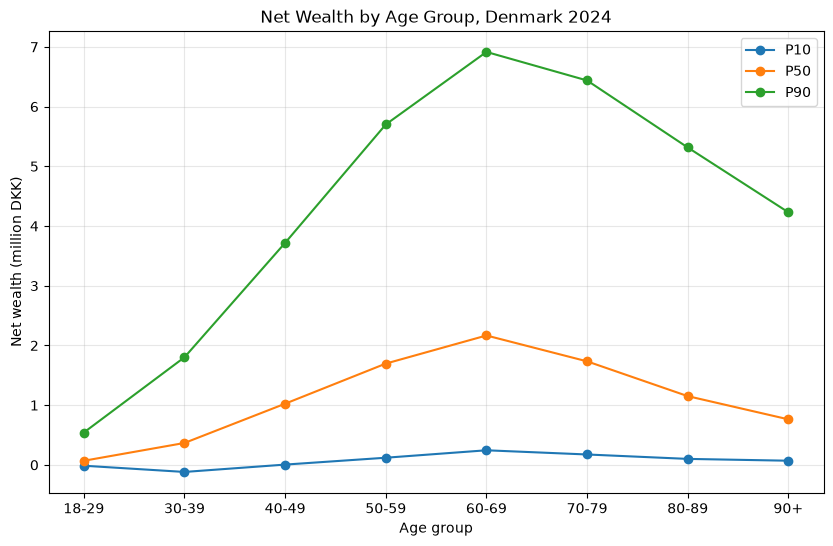

In [14]:
# 1.2 Plot the Age Profiles

# Converting percentile codes from strings to integers
percentiles_age["percentile"] = (
    percentiles_age["PERCENTIL"].str.replace("P", "").astype(int)
)

# Reshaping data: one row per age group and one column per percentile
wealth_age = percentiles_age.pivot_table(
    index="ALDER",
    columns="percentile",
    values="value"
)

# Selecting P10, P50 and P90
wealth_profile = wealth_age[[10, 50, 90]].copy()

# Defining age group labels
age_names = {
    "1829": "18-29",
    "3039": "30-39",
    "4049": "40-49",
    "5059": "50-59",
    "6069": "60-69",
    "7079": "70-79",
    "8089": "80-89",
    "9099": "90+"
}

# Ensuring that the age groups are ordered correctly
wealth_profile = wealth_profile.reindex(age_names.keys())

# Plotting the age profiles of wealth percentiles
fig, ax = plt.subplots(figsize=(10, 6))

for p in [10, 50, 90]:
    ax.plot(
        age_labels,
        wealth_profile[p] / 1_000_000,
        marker="o",
        label=f"P{p}"
    )

ax.set_xlabel("Age group")
ax.set_ylabel("Net wealth (million DKK)")
ax.set_title("Net Wealth by Age Group, Denmark 2024")
ax.legend()
ax.grid(alpha=0.3)

plt.show()


**Interpretation**

**Exercise 1.2.1.**
The figure shows the 10th, 50th and 90th percentiles (P10, P50 and P90) of net wealth for each age group in Denmark in 2024. For example, a 18–29-year-old at P90, i.e. with higher net wealth than 90 percent of the other Danes in the same age group, has a net wealth of around 0.5 million DKK. A 60–69-year-old at P90 has a net wealth of approximately 7 million DKK.

The differences between the percentiles become larger from age group 18–29 up to 60–69 and then smaller again in the older age groups. This applies to the difference between P10 and P50, between P50 and P90, and between P10 and P90. Since the data are a cross-section from 2024, the figure compares different people in different age groups, not the same people as they get older.

In [15]:
# 1.2.2 Calculating age gaps
wealth_profile["upper_gap"] = wealth_profile[90] - wealth_profile[50]
wealth_profile["lower_gap"] = wealth_profile[50] - wealth_profile[10]

wealth_profile_display = wealth_profile.rename(index=age_names)

display(
    wealth_profile_display.rename(columns={
        10: "P10",
        50: "P50",
        90: "P90",
        "upper_gap": "Upper gap",
        "lower_gap": "Lower gap"
    }).round(0)
)

display(wealth_profile)

# Find the age group with the widest upper gap
max_age = wealth_profile["upper_gap"].idxmax()
max_gap = wealth_profile.loc[max_age, "upper_gap"]

print(f"Widest upper gap: {max_age}")
print(f"Amount: {max_gap:,.0f} DKK")

percentile,P10,P50,P90,Upper gap,Lower gap
ALDER,,,,,
18-29,-14254.0,68806.0,541878.0,473072.0,83060.0
30-39,-118420.0,366935.0,1802110.0,1435175.0,485355.0
40-49,4660.0,1024656.0,3718363.0,2693707.0,1019996.0
50-59,119753.0,1696187.0,5700964.0,4004777.0,1576434.0
60-69,244332.0,2166898.0,6915373.0,4748475.0,1922566.0
70-79,174039.0,1733634.0,6437553.0,4703919.0,1559595.0
80-89,100122.0,1151164.0,5315410.0,4164246.0,1051042.0
90+,69644.0,762475.0,4229814.0,3467339.0,692831.0


percentile,10,50,90,upper_gap,lower_gap
ALDER,,,,,
1829,-14254.0,68806.0,541878.0,473072.0,83060.0
3039,-118420.0,366935.0,1802110.0,1435175.0,485355.0
4049,4660.0,1024656.0,3718363.0,2693707.0,1019996.0
5059,119753.0,1696187.0,5700964.0,4004777.0,1576434.0
6069,244332.0,2166898.0,6915373.0,4748475.0,1922566.0
7079,174039.0,1733634.0,6437553.0,4703919.0,1559595.0
8089,100122.0,1151164.0,5315410.0,4164246.0,1051042.0
9099,69644.0,762475.0,4229814.0,3467339.0,692831.0


Widest upper gap: 6069
Amount: 4,748,475 DKK


**Interpretation** 

**Exercise 1.2.2**
The largest upper wealth gap is observed in the age group 60-69, where the difference between P90 and P50 is approximately 4.74 million DKK. This indicates that there are larger wealth differences in the upper half of the wealth distribution for this age group.

In [16]:
# 1.2.3 Identifying age groups with negative P10

negative_p10 = wealth_profile[wealth_profile[10] < 0]

print("Age groups with negative P10:")
print(negative_p10.index.tolist())

Age groups with negative P10:
['1829', '3039']


**Interpretation**

**Exercise 1.2.3.**
P10 is negative for the 18–29-year-olds and the 30–39-year-olds. This means that at least 10 percent of the people in these age groups have a negative net wealth, i.e. their debt is larger than their assets.

One economic reason why young adults are more likely than older adults to have more debt than assets is that they have recently taken on large loans, for example student loans or a mortgage for their first home, while they have not yet had time to build up assets through savings, pension contributions and paying off debt. Older adults have had many more years to save and pay down their loans, so their assets are more likely to exceed their debt.

## 1.3   Who Has Negative Net Wealth?
Tasks and hints: PDF Section 1.3.

In [23]:
#Starting by finding the brackets that lie below zero. We are informed, that there are 3 breackets that lie below zero. 
from dstapi import DstApi

FORMUE15 = DstApi('FORMUE15')
FORMUE15.variable_levels('FORMUE', language='en')

display(FORMUE15.variable_levels('FORMUE', language='en'))
#The three brackets that lies below zero are 0000M10, M100M05 and M050000.
negative_brackets = ['0000M10', 'M100M05', 'M050000']


#Mark the rows that are in a negative bracket (True/False)
I = counts_age['FORMUE'].isin(negative_brackets)

#Total number of people in each age group (all brackets)
total = counts_age.groupby('ALDER')['value'].sum()

#Number of people with negative wealth in each age group (only the 3 negative brackets)
negative = counts_age.loc[I].groupby('ALDER')['value'].sum()

print(total)
print(negative)

negative_wealth = negative / total * 100
print('Share with negative net wealth (%):')
display(negative_wealth.round(1))

,id,text
0,0000M10,Under (-1.000.000 DKK)
1,M100M05,(-1.000.000 DKK) - (-500.000 DKK)
2,M050000,(-500.000 DKK) - 0 DKK
3,0000005,0 DKK - 500.000 DKK
4,0050010,500.000 DKK - 1.000.000 DKK
5,0100015,1.000.000 DKK - 1.500.000 DKK
6,0150020,1.500.000 DKK - 2.000.000 DKK
7,0200025,2.000.000 DKK - 2.500.000 DKK
8,0250030,2.500.000 DKK - 3.000.000 DKK
9,0300035,3.000.000 DKK - 3.500.000 DKK


ALDER
1829    927354
3039    783901
4049    708080
5059    802113
6069    709729
7079    581304
8089    291975
9099     47362
Name: value, dtype: int64
ALDER
1829    112690
3039    122087
4049     62699
5059     41209
6069     21947
7079     17437
8089      8636
9099       886
Name: value, dtype: int64
Share with negative net wealth (%):


ALDER
1829    12.2
3039    15.6
4049     8.9
5059     5.1
6069     3.1
7079     3.0
8089     3.0
9099     1.9
Name: value, dtype: float64

In [25]:
#Merging the counts and percentages, with the percentile table.
 
#Collect the counts and the percentage in one table
neg_table = pd.DataFrame({
    'total': total,
    'negative': negative,
    'pct_negative': negative_wealth,
})

#Turn the age group from row label into an ordinary column called ALDER
neg_table = neg_table.reset_index()
profile = wealth_profile.reset_index()

#Merge on ALDER.
combined = pd.merge(profile, neg_table, on='ALDER', how='inner', validate='1:1')

#Check the rows before and after
print('Rows:', profile.shape[0], '+', neg_table.shape[0], '->', combined.shape[0])
display(combined)

Rows: 8 + 8 -> 8


,ALDER,10,50,90,upper_gap,lower_gap,total,negative,pct_negative
0,1829,-14254.0,68806.0,541878.0,473072.0,83060.0,927354,112690,12.151778
1,3039,-118420.0,366935.0,1802110.0,1435175.0,485355.0,783901,122087,15.574288
2,4049,4660.0,1024656.0,3718363.0,2693707.0,1019996.0,708080,62699,8.854790
3,5059,119753.0,1696187.0,5700964.0,4004777.0,1576434.0,802113,41209,5.137555
4,6069,244332.0,2166898.0,6915373.0,4748475.0,1922566.0,709729,21947,3.092307
5,7079,174039.0,1733634.0,6437553.0,4703919.0,1559595.0,581304,17437,2.999635
6,8089,100122.0,1151164.0,5315410.0,4164246.0,1051042.0,291975,8636,2.957787
7,9099,69644.0,762475.0,4229814.0,3467339.0,692831.0,47362,886,1.870698


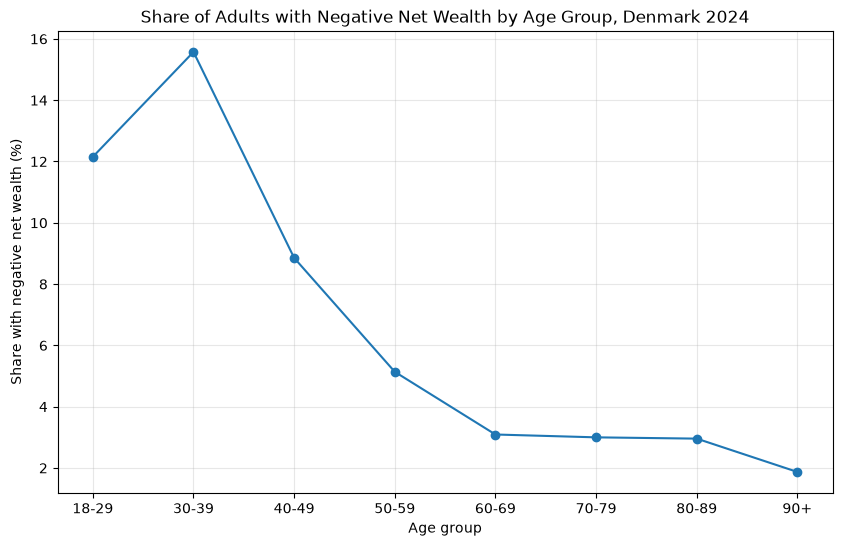

In [26]:
#Plotting the percentage by age.
#Making readable age labels for the x-axis
age_labels = ["18-29", "30-39", "40-49", "50-59",
              "60-69", "70-79", "80-89", "90+"]

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(age_labels, combined['pct_negative'], marker="o")

ax.set_xlabel("Age group")
ax.set_ylabel("Share with negative net wealth (%)")
ax.set_title("Share of Adults with Negative Net Wealth by Age Group, Denmark 2024")
ax.grid(alpha=0.3)

plt.show()

**Interpretation.** Write your answer here.

The share of people with negative net wealth increases only between the two youngest age groups, from about 12 percent among the 18–29-year-olds to a peak of about 16 percent among the 30–39-year-olds. This makes sense, since many people in their 30s have recently taken out a large loan, for example a mortgage for their first home. After 30–39 the share decreases markedly, and it is lowest for the 90+-year-olds at around 2 percent. So every age group has some people with negative net wealth, but after 30–39 the share is lower the older the age group.

The median profile (the P50 line in the figure in 1.2) shows a different pattern. Median net wealth increases strongly from about 0.1 million DKK for the 18–29-year-olds to about 2.2 million DKK for the 60–69-year-olds and then decreases in the older age groups. 

Between 30–39 and 60–69 the two profiles move in opposite directions. The median increases while the share with negative wealth decreases. After 60–69, however, both decrease. The median falls, but the share with negative wealth does not rise again. 

The two profiles also peak in different age groups. The share with negative wealth at 30–39 and the median at 60–69. Since the data are a cross-section from 2024, these differences are between different people in different age groups, not changes for the same people as they get older.

In [27]:
#Checking that the eight age counts sum to the published all-adult count.
#Adding up the 8 age groups.
sum_age_groups = total.sum()

#Adding up all brackets for all adults (ALDER = '1802')
all_adults = counts_all['value'].sum()

print(f"Sum of the eight age groups: {sum_age_groups:,}")
print(f"Published all-adult count:   {all_adults:,}")
print("Match:", sum_age_groups == all_adults)

Sum of the eight age groups: 4,851,818
Published all-adult count:   4,851,818
Match: True


## 2.1   Give Everybody Their Age-Group Median
Tasks and hints: PDF Section 2.1.

In [11]:
# Write your simulation function in a .py file next to this notebook and import it here.

**Interpretation.** Write your answer here.

## 2.2   Allow Wealth to Vary Within Each Age Group
Tasks and hints: PDF Section 2.2.

## 2.3   Compare Both Economies with Denmark
Tasks and hints: PDF Section 2.3.

**Interpretation.** Write your answer here.

## 2.4   An Older Denmark
Tasks and hints: PDF Section 2.4.

**Interpretation.** Write your answer here.

Data: [StatBank FORMUE16](https://www.statbank.dk/FORMUE16) and [StatBank FORMUE15](https://www.statbank.dk/FORMUE15).